# Heart Disease Prediction ML Project

**📝 Problem Statement**

* The objective of this project is to build an end-to-end predictive machine learning model to diagnose coronary heart disease using patient clinical indicators from the Heart_Disease_Prediction.csv dataset. 
* By analyzing structural patient demographics (age, sex), baseline metrics (bp, cholesterol, fbs_over_120), and advanced physiological/stress test evaluations (chest_pain_type, ekg_results, max_hr, exercise_angina, st_depression, slope_of_st, number_of_vessels_fluro, thallium), the system uncovers vital clinical warning signs. 
* This predictive classification pipeline is designed to accurately predict the presence or absence of cardiac pathology (heart_disease). 
* This clinical framework enables healthcare practitioners to flag high-risk individuals early, reducing diagnostic delays and allowing for proactive treatment plans.

**Step 1: Import Libraries**

In [2]:
# System and Data manipulation
import joblib

# Visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier

# feature selection
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer

# Classification Models
from sklearn.linear_model import LogisticRegression

# Classification Metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

# Preprocessing & Selection
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier


**Step 2: Load Dataset**

In [37]:
df = pd.read_csv("Heart_Disease_Prediction.csv")

**Step 3: Understand Your Data (EDA)**

In [5]:
print("\n[First 5 Rows Preview]:\n")
df.head()


[First 5 Rows Preview]:



,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,Presence
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,Absence
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,Presence
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,Absence
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,Absence


In [7]:
print(f"\n[Dataset Dimensions (Rows, Columns)]: {df.shape}")


[Dataset Dimensions (Rows, Columns)]: (270, 14)


In [13]:
df.columns

Index(['Age', 'Sex', 'Chest pain type', 'BP', 'Cholesterol', 'FBS over 120',
       'EKG results', 'Max HR', 'Exercise angina', 'ST depression',
       'Slope of ST', 'Number of vessels fluro', 'Thallium', 'Heart Disease'],
      dtype='str')

In [15]:
df.dtypes

Age                          int64
Sex                          int64
Chest pain type              int64
BP                           int64
Cholesterol                  int64
FBS over 120                 int64
EKG results                  int64
Max HR                       int64
Exercise angina              int64
ST depression              float64
Slope of ST                  int64
Number of vessels fluro      int64
Thallium                     int64
Heart Disease                  str
dtype: object

In [14]:
df.nunique()

Age                         41
Sex                          2
Chest pain type              4
BP                          47
Cholesterol                144
FBS over 120                 2
EKG results                  3
Max HR                      90
Exercise angina              2
ST depression               39
Slope of ST                  3
Number of vessels fluro      4
Thallium                     3
Heart Disease                2
dtype: int64

In [8]:
print("\n[Data Types and Structural Check]:")
df.info()


[Data Types and Structural Check]:
<class 'pandas.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      270 non-null    int64  
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              270 non-null    int64  
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            270 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    str    
dtypes

In [9]:
print("\n[Descriptive Statistical Summary]:\n")
df.describe().T


[Descriptive Statistical Summary]:



,count,mean,std,min,25%,50%,75%,max
Age,270.0,54.433333,9.109067,29.0,48.0,55.0,61.0,77.0
Sex,270.0,0.677778,0.468195,0.0,0.0,1.0,1.0,1.0
Chest pain type,270.0,3.174074,0.950090,1.0,3.0,3.0,4.0,4.0
BP,270.0,131.344444,17.861608,94.0,120.0,130.0,140.0,200.0
Cholesterol,270.0,249.659259,51.686237,126.0,213.0,245.0,280.0,564.0
FBS over 120,270.0,0.148148,0.355906,0.0,0.0,0.0,0.0,1.0
EKG results,270.0,1.022222,0.997891,0.0,0.0,2.0,2.0,2.0
Max HR,270.0,149.677778,23.165717,71.0,133.0,153.5,166.0,202.0
Exercise angina,270.0,0.329630,0.470952,0.0,0.0,0.0,1.0,1.0
ST depression,270.0,1.050000,1.145210,0.0,0.0,0.8,1.6,6.2


In [12]:
print("\n[Target Variable Value Counts]:")
print(df['Heart Disease'].value_counts())


[Target Variable Value Counts]:
Heart Disease
Absence     150
Presence    120
Name: count, dtype: int64


**Step 4: Data Cleaning**

In [16]:
# 1. Remove Duplicates
print(f"Duplicate rows identified: {df.duplicated().sum()}")
df = df.drop_duplicates()

Duplicate rows identified: 0


In [ ]:
# 2. Remove Unwanted Columns
# there no unwanted col

In [18]:
# 3. Check for Missing Values 
print("Missing values per parameter:\n", df.isnull().sum())

Missing values per parameter:
 Age                        0
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                0
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              0
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64


In [ ]:
# 4. Fix Data Types
# No need

In [38]:
# 5. Fix proper col names
df = df.rename(columns={
    'Age':'age',
    'Sex':'sex',
    'Chest pain type':'chest_pain_type',
    'BP':'bp',
    'Cholesterol':'cholesterol',
    'FBS over 120':'fbs_over_120',
    'EKG results':'ekg_results',
    'Max HR':'max_hr',
    'Exercise angina':'exercise_angina',
    'ST depression':'st_depression',
    'Slope of ST':'slope_of_st',
    'Number of vessels fluro':'number_of_vessels_fluro',
    'Thallium':'thallium',
    'Heart Disease':'heart_disease'
})

<Axes: >

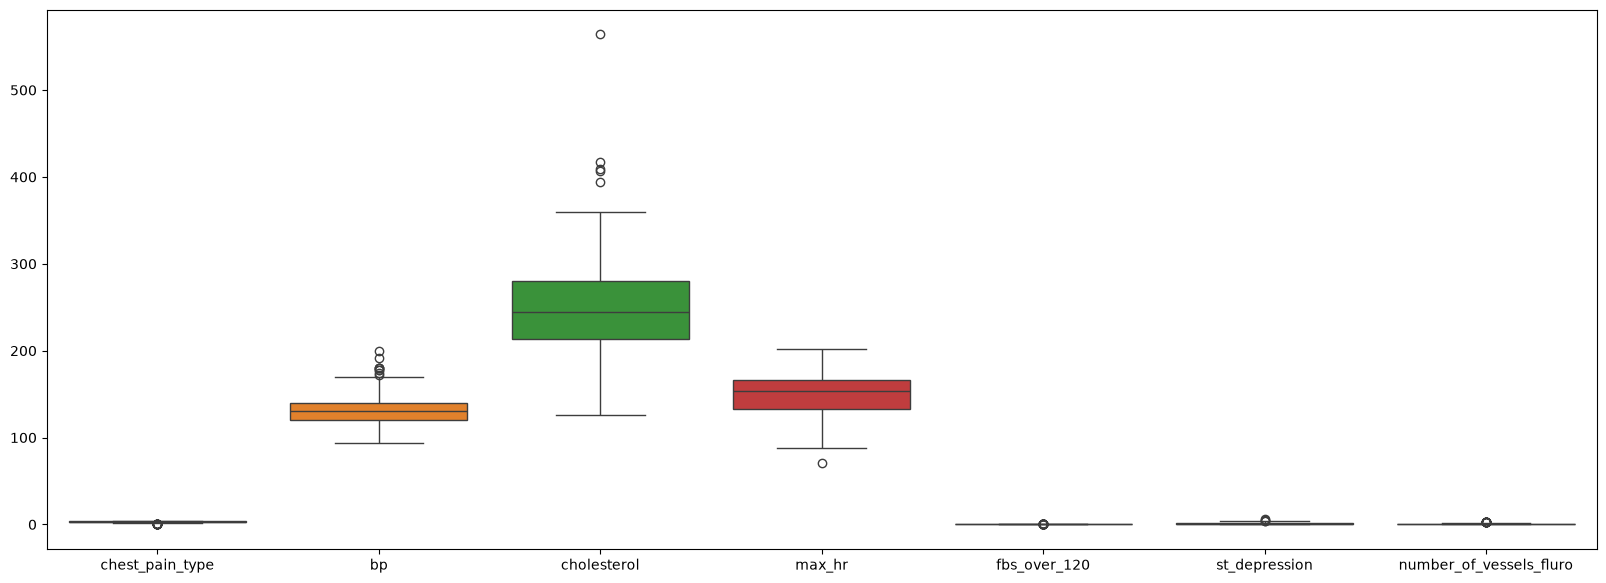

In [41]:
# 6. Remove outliers
plt.figure(figsize=(20,7))
sns.boxplot(df[['chest_pain_type','bp', 'cholesterol', 'max_hr','fbs_over_120','st_depression','number_of_vessels_fluro']])

In [42]:
cols = ['chest_pain_type','bp', 'cholesterol', 'max_hr','fbs_over_120','st_depression','number_of_vessels_fluro']

for i,col in enumerate(cols,start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)

    before_outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"\n{i}. {col}")
    print("before outliers: ",len(before_outliers))
    df[col] = df[col].clip(lower,upper)
    after_outliers = df[(df[col] < lower) | (df[col] > upper)]
    print("after outliers: ",len(after_outliers))


1. chest_pain_type
before outliers:  20
after outliers:  0

2. bp
before outliers:  9
after outliers:  0

3. cholesterol
before outliers:  5
after outliers:  0

4. max_hr
before outliers:  1
after outliers:  0

5. fbs_over_120
before outliers:  40
after outliers:  0

6. st_depression
before outliers:  4
after outliers:  0

7. number_of_vessels_fluro
before outliers:  19
after outliers:  0


**verify:**

<Axes: >

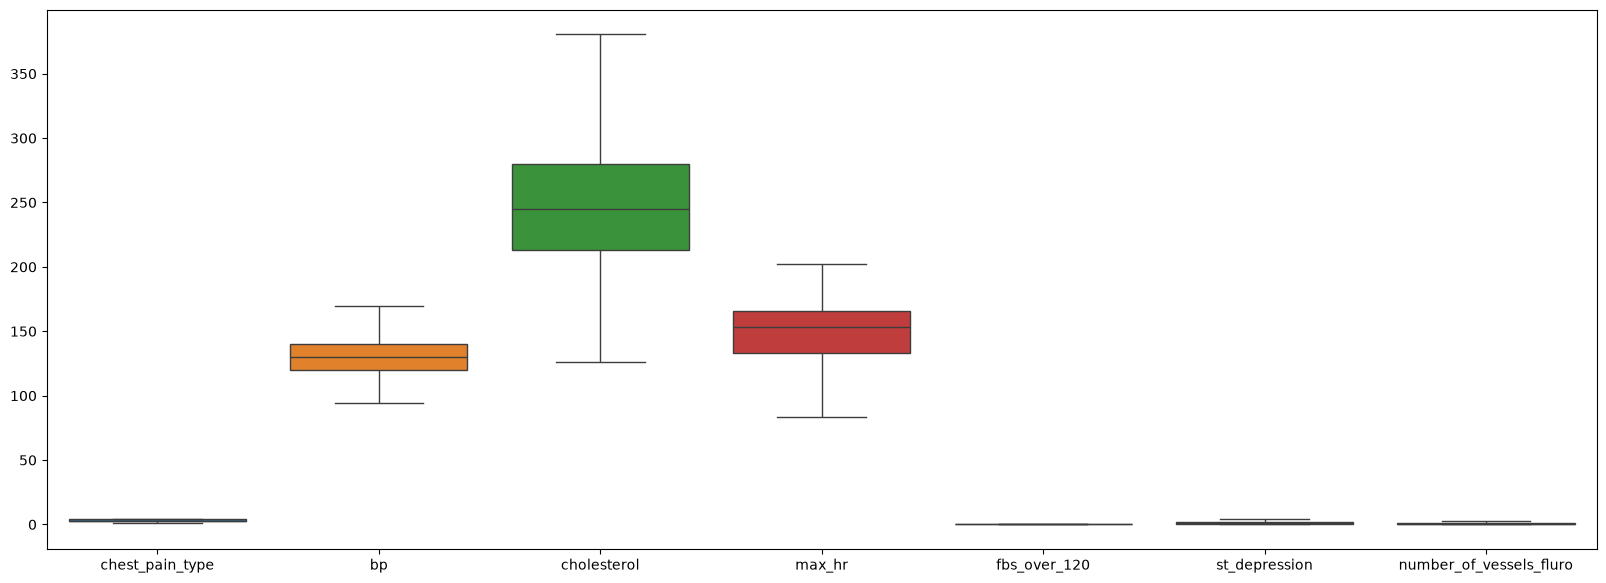

In [43]:
plt.figure(figsize=(20,7))
sns.boxplot(df[['chest_pain_type','bp', 'cholesterol', 'max_hr','fbs_over_120','st_depression','number_of_vessels_fluro']])

**Step 5: Feature Engineering**

In [44]:
df['bp_cholesterol_risk'] = df['bp'] * df['cholesterol']

df['estimated_hr_reserve'] = (220 - df['age']) - df['max_hr']

**Step 6: Data Visualization**

Univariate:

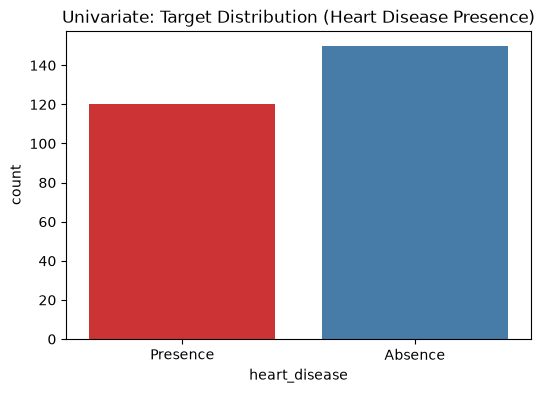

In [45]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='heart_disease', palette='Set1',hue='heart_disease')
plt.title('Univariate: Target Distribution (Heart Disease Presence)')
plt.show()

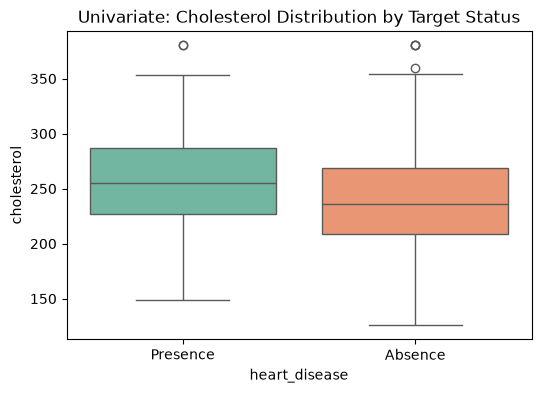

In [31]:
# 2. Univariate: Boxplot (Cholesterol Distibution across targets)
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='heart_disease', y='cholesterol', palette='Set2', hue='heart_disease')
plt.title('Univariate: Cholesterol Distribution by Target Status')
plt.show()

Bivariate & Multivariate:

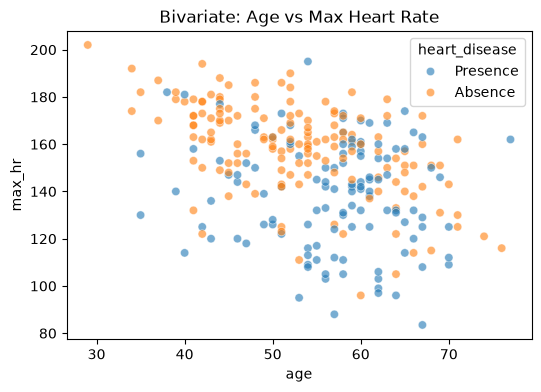

In [47]:
# 3. Bivariate: Scatterplot (Age vs Max Heart Rate split by Target)
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='age', y='max_hr', hue='heart_disease', alpha=0.6)
plt.title('Bivariate: Age vs Max Heart Rate')
plt.show()

Correlation analysis:

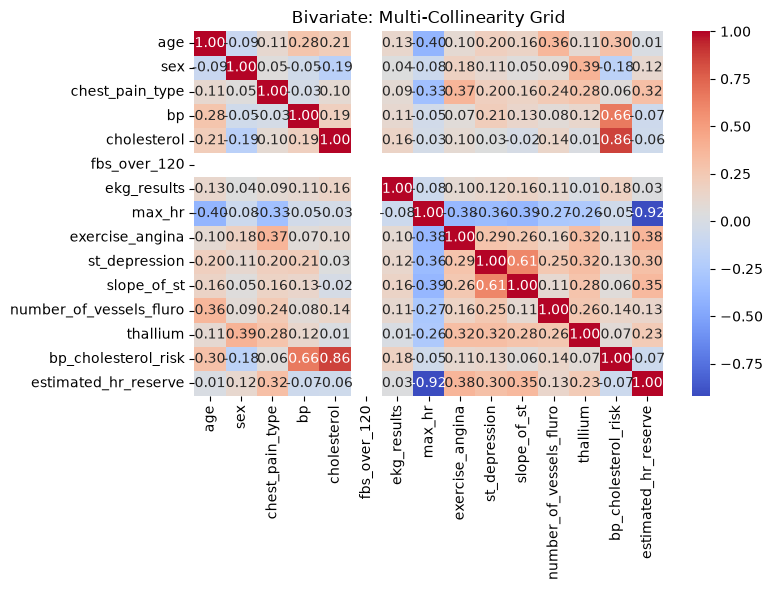

In [50]:
# 4. Bivariate: Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[int,float])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Bivariate: Multi-Collinearity Grid')
plt.tight_layout()
plt.show()

**Step 7: Define Features (X) and Target (y)**

In [55]:
X = df.drop(columns=['heart_disease'])

le = LabelEncoder()
y = le.fit_transform(df['heart_disease'])

numeric_cols = X.select_dtypes(include=[int,float]).columns.tolist()
categorical_cols = X.select_dtypes(include=['str', 'category']).columns.tolist()

**Step 8: Train-Test Split**

In [56]:
# Partition into 80% Training and 20% Testing subsets (Using stratify to maintain balanced medical classes)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

X_train Shape: (216, 15) | X_test Shape: (54, 15)


**Step 9: Preprocessing Pipeline**

In [57]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

**Step 10: Feature Selection**

In [58]:
# Initialize VarianceThreshold
selector = VarianceThreshold(threshold=0.01)

# Fit and transform the data
X_train_sele = selector.fit_transform(X_train_processed)
X_test_sele = selector.fit_transform(X_test_processed)

print("Original X Train shape:", X_train_processed.shape)
print("Reduced X Train shape:", X_train_sele.shape)
print("Reduced X Test shape:", X_test_sele.shape)

Original X Train shape: (216, 15)
Reduced X Train shape: (216, 14)
Reduced X Test shape: (54, 14)


**Step 11 & 12: Train Models & Regression Metrics**

In [62]:
classification_suite = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6,min_samples_split=5, min_samples_leaf=2, max_features=None, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=2, min_samples_leaf=1, random_state=42, n_jobs=-1),
    "XGBoost Classifier": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42)
}

for name, model in classification_suite.items():
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, zero_division=0)
    rec = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    
    print(f"[{name}] -> Accuracy: {acc*100:.2f}% | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")


[Logistic Regression] -> Accuracy: 85.19% | Precision: 0.8077 | Recall: 0.8750 | F1: 0.8400
[Decision Tree] -> Accuracy: 75.93% | Precision: 0.7200 | Recall: 0.7500 | F1: 0.7347
[Random Forest] -> Accuracy: 81.48% | Precision: 0.7692 | Recall: 0.8333 | F1: 0.8000
[XGBoost Classifier] -> Accuracy: 81.48% | Precision: 0.7692 | Recall: 0.8333 | F1: 0.8000


In [63]:
classification_suite = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6,min_samples_split=5, min_samples_leaf=2, max_features=None, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_split=4, min_samples_leaf=1, random_state=42, n_jobs=-1),
    "XGBoost Classifier": XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
}

for name, model in classification_suite.items():
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, zero_division=0)
    rec = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    
    print(f"[{name}] -> Accuracy: {acc*100:.2f}% | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")


[Logistic Regression] -> Accuracy: 85.19% | Precision: 0.8077 | Recall: 0.8750 | F1: 0.8400
[Decision Tree] -> Accuracy: 75.93% | Precision: 0.7200 | Recall: 0.7500 | F1: 0.7347
[Random Forest] -> Accuracy: 81.48% | Precision: 0.7692 | Recall: 0.8333 | F1: 0.8000
[XGBoost Classifier] -> Accuracy: 81.48% | Precision: 0.7692 | Recall: 0.8333 | F1: 0.8000


**Step 13: Cross Validation**

In [64]:
lr_validator = LogisticRegression(max_iter=1000, random_state=42)
cv_scores = cross_val_score(lr_validator, X_train_processed, y_train, cv=3, scoring='accuracy')

print(f"3-Fold Cross Validation Individual Accuracy Matrix: {cv_scores}")
print(f"Mean Generalization Accuracy Performance: {cv_scores.mean()*100:.2f}%")


3-Fold Cross Validation Individual Accuracy Matrix: [0.77777778 0.88888889 0.875     ]
Mean Generalization Accuracy Performance: 84.72%


**Step 14: Hyperparameter Tuning**

In [82]:
from sklearn.model_selection import GridSearchCV

lr_to_tune = LogisticRegression(max_iter=1000, random_state=42)

param_grid = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 50.0],
    'l1_ratio': [0.2, 0.5, 0.7],                   
    'solver': ['saga']          
}

grid_search = GridSearchCV(
    estimator=lr_to_tune,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_processed, y_train)
best_tuned_classifier = grid_search.best_estimator_

print("Optimal Hyperparameter Configurations Found:", grid_search.best_params_)


Optimal Hyperparameter Configurations Found: {'C': 0.1, 'l1_ratio': 0.2, 'solver': 'saga'}


In [84]:
predictions = best_tuned_classifier.predict(X_test_processed)
acc = accuracy_score(y_test, predictions)

print(f"[Tuned Logistic] -> Accuracy: {acc*100:.2f}%")

[Tuned Logistic] -> Accuracy: 85.19%


**Step 15: Feature Importance**

In [ ]:
raw_features = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    'Feature': raw_features,
    'Importance': np.abs(best_tuned_classifier.coef_[0])  # Take absolute values for magnitude
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP LOGISTIC REGRESSION FEATURE IMPORTANCE SCORES ---")
print(importance.to_string(index=False))


--- TOP LOGISTIC REGRESSION FEATURE IMPORTANCE SCORES ---
                     Feature  Importance
num__number_of_vessels_fluro    0.694873
        num__chest_pain_type    0.533120
               num__thallium    0.502207
                    num__sex    0.483169
        num__exercise_angina    0.320575
          num__st_depression    0.264287
    num__bp_cholesterol_risk    0.224143
            num__slope_of_st    0.211420
                 num__max_hr    0.209262
   num__estimated_hr_reserve    0.127005
            num__cholesterol    0.070800
            num__ekg_results    0.061119
                     num__bp    0.037162
                    num__age    0.026871
           num__fbs_over_120    0.000000


**Step 16: Final Pipeline Production**

In [87]:
print("Comprehensive automated classification pipeline constructed successfully!")

model_artifact = {
    "model_pipeline": Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', best_tuned_classifier)
    ]),
    "feature_names": X.columns.tolist(),
    "label_encoder": le
}

model_artifact["model_pipeline"].fit(X_train, y_train)

Comprehensive automated classification pipeline constructed successfully!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','sex','chest_pain_type',...,'thallium','bp_cholesterol_risk', 'estimated_hr_reserve']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

**Step 17: Save Model & Load Model**

In [89]:
# Serialize artifact deployment bundle onto disk directly inside the current working directory
joblib.dump(model_artifact, "heart_logistic.pkl")
print("Production artifact saved successfully as 'heart_logistic.pkl'")

Production artifact saved successfully as 'heart_logistic.pkl'


In [90]:
# Test loading structural configuration package integrity
loaded_bundle = joblib.load("heart_logistic.pkl")
production_ready_pipeline = loaded_bundle["model_pipeline"]
print("Model validation verified successfully! Code ready for production web app routing layers.")


Model validation verified successfully! Code ready for production web app routing layers.
